# Chapitre 9 - Exercices 9.7 à 9.12

Ce notebook traite six exercices sur le décodage, l'attention et le service :

- **9.7** : accélération du décodage spéculatif, de la formule à la mesure ;
- **9.8** : cache KV de Llama 3-70B et nombre d'utilisateurs simultanés ;
- **9.9** : PagedAttention, choisir la taille des blocs ;
- **9.10** : batching dynamique, régler la fenêtre ;
- **9.11** : rentabilité du cache de prompt (stockage, durée de vie) et mesure du TTFT ;
- **9.12** : répartir Llama 3-70B sur 8 GPU (tenseur, pipeline, répliques).

In [1]:
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie import llm
from aie import ch09_inference as inf
from aie.ch02_modeles import KNOWN_CONFIGS, count_params_config, kv_cache_bytes, plain_log_axis
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT, COLORS,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore")
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.precision", 3)
H100 = inf.ACCELERATORS["H100 SXM"]
GB = 1e9

## Exercice 9.7 : Accélération du décodage spéculatif

**Énoncé.**

1. On suppose que chaque token proposé est accepté avec probabilité $\alpha$,
   indépendamment, tant que les précédents l'ont été. Montrer que le nombre $J$ de tokens
   acceptés sur $k$ proposés suit $P(J = j) = \alpha^j(1 - \alpha)$ pour $j < k$ et
   $P(J = k) = \alpha^k$, puis que $\mathbb{E}[1 + J] = \frac{1 - \alpha^{k+1}}{1 - \alpha}$.
2. Exemple du livre (Chen et al., 2023) : brouillon de 4 milliards de paramètres à
   1,8 ms/token, cible Chinchilla-70B à 14,1 ms/token. Pour $\alpha = 0{,}8$, quel $k$
   maximise l'accélération ? La latence est-elle réduite « de plus de moitié » ?
3. Mini-lab : avec Qwen2.5-0.5B (brouillon) et Qwen2.5-1.5B (cible), $k = 6$, comparer la
   distribution observée de $J$ à la loi géométrique tronquée ajustée.

**Rappels.** Décodage spéculatif (cours 2, section 7 ; section *Speculative decoding*) :
accélération $S = \mathbb{E}[1 + J]/(kc + 1)$ avec $c$ le coût relatif d'un pas du
brouillon. Estimateur de $\alpha$ : acceptations / (acceptations + rejets).

**Solution.**

1. $J = j < k$ signifie : les $j$ premiers tokens acceptés (probabilité $\alpha^j$), puis
   un rejet ($1 - \alpha$) ; $J = k$ : tous acceptés, $\alpha^k$. Alors
   $P(J \ge i) = \alpha^i$ pour $1 \le i \le k$ et
   $\mathbb{E}[J] = \sum_{i=1}^{k} P(J \ge i) = \sum_{i=1}^{k} \alpha^i$, d'où
   $\mathbb{E}[1 + J] = \sum_{i=0}^{k} \alpha^i = \frac{1 - \alpha^{k+1}}{1 - \alpha}$.
   $\blacksquare$
2. $c = 1{,}8 / 14{,}1 \approx 0{,}128$. On évalue $S(k)$ pour $k = 1, \dots, 12$ :

c = 0.128 ; k optimal = 5 ; accélération = 2.25 -> latence x 0.44


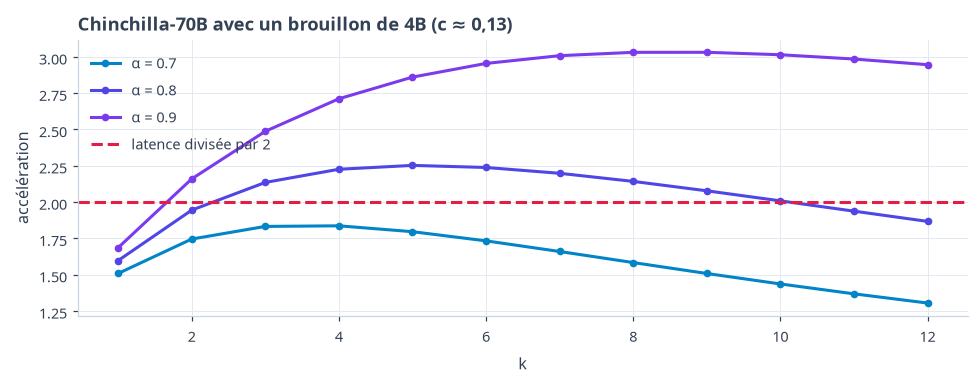

In [2]:
c_book = 1.8 / 14.1
ks = np.arange(1, 13)
S = inf.speculative_speedup(0.8, ks, c_book)
k_opt = inf.optimal_k(0.8, c_book)
print(f"c = {c_book:.3f} ; k optimal = {k_opt} ; accélération = {S[k_opt - 1]:.2f}"
      f" -> latence x {1 / S[k_opt - 1]:.2f}")
fig, ax = plt.subplots(figsize=(9, 3.6))
for a, col in [(0.7, SKY), (0.8, INDIGO), (0.9, VIOLET)]:
    ax.plot(ks, inf.speculative_speedup(a, ks, c_book), "o-", ms=4, color=col, label=f"α = {a}")
ax.axhline(2, color=ROSE, ls="--", label="latence divisée par 2")
ax.set_xlabel("k"); ax.set_ylabel("accélération"); ax.legend()
ax.set_title("Chinchilla-70B avec un brouillon de 4B (c ≈ 0,13)")
plt.tight_layout(); plt.show()

Avec $\alpha = 0{,}8$, l'optimum est vers $k = 4$ à 5 et l'accélération dépasse 2 : la
latence est bien plus que divisée par deux, conforme au livre. Avec $\alpha = 0{,}7$, on
reste sous 2 : le résultat est sensible au taux d'acceptation, donc au domaine.

**Vérification expérimentale** (question 3).

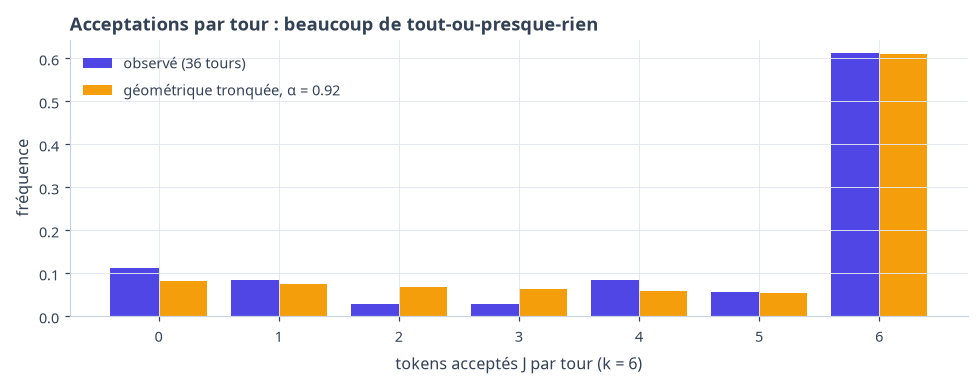

tokens par passe de la cible : mesuré 5.41, formule 5.53


In [3]:
tok_t, tgt = inf.retry_oom(llm.load, llm.MEDIUM)
tok_d, drf = inf.retry_oom(llm.load, llm.SMALL)
stop = inf.eos_ids(tok_t)
p = "Write a short Python class `Stack` with push, pop and peek methods, and a docstring for each."
ids_p = llm._chat_inputs(tok_t, p)["input_ids"][0].tolist()
r = inf.retry_oom(inf.assisted_generate, tgt, ids_p, inf.DraftModelProposer(drf), k=6, max_new_tokens=200, stop=stop)
J = np.array(r.rounds); P = np.array(r.proposed)
full = J[P == 6]  # tours complets (k = 6 propositions)
a_hat = inf.estimate_alpha(full, np.full_like(full, 6))
j_vals = np.arange(7)
theo = np.array([a_hat ** j * (1 - a_hat) for j in range(6)] + [a_hat ** 6])
obs = np.array([(full == j).mean() for j in j_vals])
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(j_vals - 0.2, obs, 0.4, color=INDIGO, label=f"observé ({len(full)} tours)")
ax.bar(j_vals + 0.2, theo, 0.4, color=AMBER, label=f"géométrique tronquée, α = {a_hat:.2f}")
ax.set_xlabel("tokens acceptés J par tour (k = 6)"); ax.set_ylabel("fréquence"); ax.legend()
ax.set_title("Acceptations par tour : beaucoup de tout-ou-presque-rien")
plt.tight_layout(); plt.show()
print(f"tokens par passe de la cible : mesuré {len(r.tokens) / r.forwards:.2f},"
      f" formule {float(inf.expected_tokens_per_round(a_hat, 6)):.2f}")

La forme générale (beaucoup de tours entièrement acceptés, un pic à $J = 0$) est bien
celle d'une géométrique tronquée, mais les écarts montrent que l'hypothèse
d'indépendance est approximative : les acceptations viennent **par séries** (passages
faciles, comme la syntaxe d'une classe Python, puis passages difficiles). La formule
donne néanmoins le bon ordre de grandeur pour le nombre de tokens par passe, qui est ce
qui compte pour l'accélération.

> **À retenir.** $\mathbb{E}[\text{tokens par tour}] = \frac{1-\alpha^{k+1}}{1-\alpha}$ ;
> l'accélération exige $\alpha$ élevé **et** $c$ faible, et le $k$ optimal croît avec
> $\alpha$. Mesurez $\alpha$ sur votre propre trafic : il dépend du domaine.

In [4]:
llm.free_gpu()
del tgt, drf

## Exercice 9.8 : Cache KV de Llama 3-70B et utilisateurs simultanés

**Énoncé.** Llama 3-70B : 80 couches, 64 têtes de requêtes, 8 têtes KV (GQA) de dimension
128. On le sert en bf16 sur un nœud de 8 H100 (640 Go), en gardant 10 % de marge.

1. Taille du cache KV par token et par séquence de 128k tokens.
2. Nombre maximal d'utilisateurs simultanés à 128k, 32k et 8k tokens de contexte.
3. Mêmes questions avec un cache quantifié en fp8, puis avec une attention multi-têtes
   classique (64 têtes KV). Que conclure ?

**Rappels.** Cache KV $= 2 \cdot L \cdot h_{kv} \cdot d_h \cdot M$ octets par token
(encadré *Calculating the KV Cache Size* ; cours 3, sections 2 et 3).

**Solution.**

1. $2 \times 80 \times 8 \times 128 \times 2 = 327\,680$ octets par token (320 Kio), soit
   $\approx 43$ Go pour 128k tokens.
2. Mémoire disponible : $0{,}9 \times 640 - 141 \approx 435$ Go ; à 128k tokens :
   $435 / 43 \approx 10$ utilisateurs ; à 32k : environ 40 ; à 8k : environ 165.
3. fp8 double ces nombres ; une attention multi-têtes les divise par 8 : à 128k tokens,
   **un** utilisateur (344 Go de cache) ! Sans GQA, les longs contextes seraient
   impraticables. $\blacksquare$

variante,Kio / token,utilisateurs à 128k,utilisateurs à 32k,utilisateurs à 8k
"GQA-8, bf16",320,10,40,162
"GQA-8, cache fp8",160,20,81,324
"MHA (64 KV), bf16",2560,1,5,20


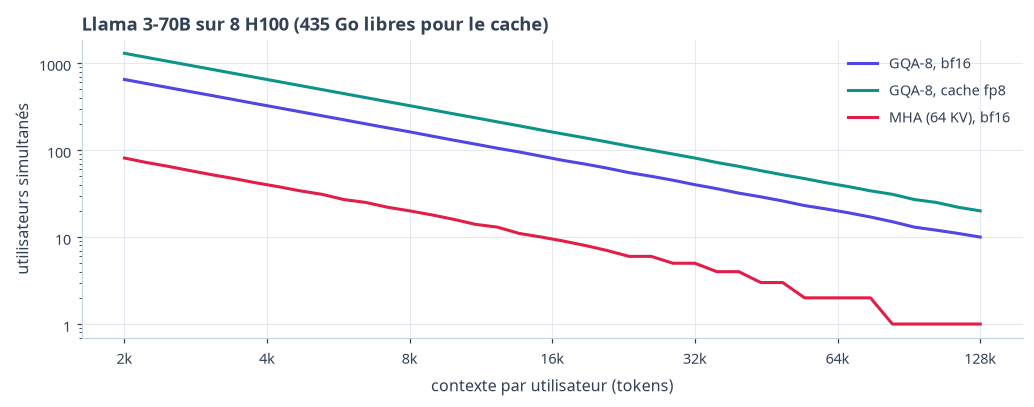

In [5]:
cfg70 = KNOWN_CONFIGS["Llama 3-70B"]
W70 = count_params_config(cfg70) * 2
free_mem = 0.9 * 8 * 80e9 - W70
rows = []
for name, nkv, bpe in [("GQA-8, bf16", 8, 2), ("GQA-8, cache fp8", 8, 1), ("MHA (64 KV), bf16", 64, 2)]:
    per_tok = inf.kv_cache_bytes_gqa(1, 1, cfg70.n_layers, nkv, cfg70.head_dim, bytes_per=bpe)
    rows.append({"variante": name, "Kio / token": per_tok / 1024,
                 **{f"utilisateurs à {S // 1024}k": int(free_mem // (per_tok * S)) for S in [131072, 32768, 8192]}})
assert rows[0]["Kio / token"] == kv_cache_bytes(cfg70, 1) / 1024  # cohérent avec le chapitre 2
display(pd.DataFrame(rows).style.format({"Kio / token": "{:.0f}"}).hide(axis="index"))
ctx = np.geomspace(2048, 131072, 40)
fig, ax = plt.subplots(figsize=(9.5, 3.8))
for (name, nkv, bpe), c in zip([("GQA-8, bf16", 8, 2), ("GQA-8, cache fp8", 8, 1), ("MHA (64 KV), bf16", 64, 2)],
                               [INDIGO, TEAL, ROSE]):
    per_tok = inf.kv_cache_bytes_gqa(1, 1, cfg70.n_layers, nkv, cfg70.head_dim, bytes_per=bpe)
    ax.plot(ctx, np.floor(free_mem / (per_tok * ctx)), color=c, label=name)
ax.set_xscale("log", base=2); ax.set_yscale("log")
plain_log_axis(ax, "x", fmt=lambda v: f"{v / 1024:g}k"); plain_log_axis(ax, "y")
ax.set_xlabel("contexte par utilisateur (tokens)"); ax.set_ylabel("utilisateurs simultanés")
ax.set_title(f"Llama 3-70B sur 8 H100 ({free_mem / GB:.0f} Go libres pour le cache)"); ax.legend()
plt.tight_layout(); plt.show()

> **À retenir.** Le nombre d'utilisateurs simultanés est inversement proportionnel au
> contexte et à la taille du cache par token : GQA (÷ 8) et un cache fp8 (÷ 2) ne sont pas
> des détails, ils décident de la viabilité économique des longs contextes.

## Exercice 9.9 : PagedAttention, choisir la taille des blocs

**Énoncé.**

1. Avec des blocs de $b$ tokens, une séquence de longueur $L$ occupe
   $\lceil L/b \rceil$ blocs. Montrer que si $L \bmod b$ est uniforme sur
   $\{0, \dots, b-1\}$, le gaspillage moyen par séquence est $\frac{b-1}{2}$ tokens
   (en comptant un gaspillage nul quand $L$ est multiple de $b$).
2. Vérifier par simulation (1 000 séquences de longueurs log-normales) pour
   $b \in \{1, 4, 16, 64, 256\}$.
3. La table des blocs coûte 4 octets par bloc et par séquence ; pour Qwen2.5-0.5B (12 Kio
   de cache par token), comparer ce coût au gaspillage. Quelle taille de bloc choisir ?

**Rappels.** PagedAttention (cours 3, section 4 ; section *Optimizing the KV cache size*) :
le gaspillage se limite au dernier bloc de chaque séquence.

**Solution.**

1. Le gaspillage vaut $b - (L \bmod b)$ si $L \bmod b \neq 0$, et 0 sinon. Avec
   $r = L \bmod b$ uniforme : $\mathbb{E} = \frac{1}{b}\sum_{r=1}^{b-1}(b - r)
   = \frac{1}{b}\cdot\frac{(b-1)b}{2} = \frac{b-1}{2}$. $\blacksquare$
2. et 3. : simulation ci-dessous. Le coût de la table, $4\lceil L/b\rceil$ octets, est
   négligeable devant le gaspillage ($12\,288 \times (b-1)/2$ octets) dès que $b > 1$ ;
   mais de tout petits blocs fragmentent les accès mémoire du noyau d'attention (lectures
   non contiguës), d'où le compromis pratique de vLLM : 16 tokens.

bloc b,gaspillage moyen (tokens),théorie (b-1)/2,gaspillage (% de la mémoire),table des blocs (octets/séq.),gaspillage (octets/séq.)
1,0.0,0.0,0.00,"2,600",0
4,1.5,1.5,0.22,652,"17,940"
16,7.3,7.5,1.11,164,"89,309"
64,31.7,31.5,4.65,43,"389,923"
256,126.1,127.5,16.24,12,"1,549,124"


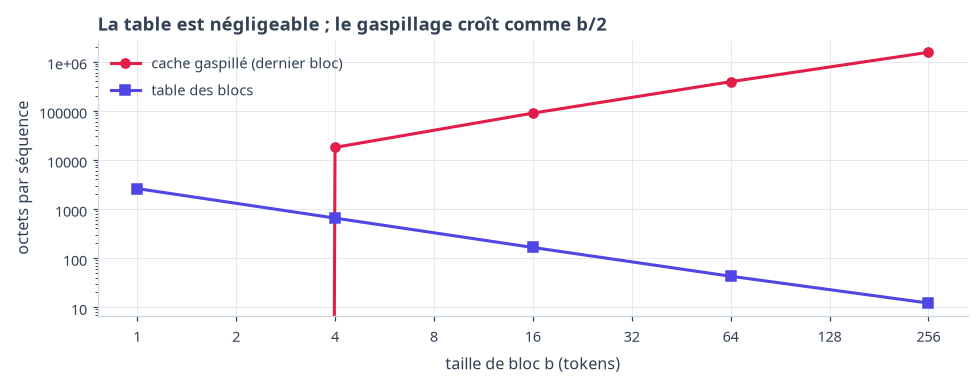

In [6]:
L = np.exp(rng.normal(np.log(500), 0.8, 1000)).astype(int).clip(10, 8000)
kv_tok = kv_cache_bytes(KNOWN_CONFIGS["Qwen2.5-0.5B"], 1)
rows = []
for b in [1, 4, 16, 64, 256]:
    waste = (np.ceil(L / b) * b - L)
    rows.append({"bloc b": b, "gaspillage moyen (tokens)": waste.mean(), "théorie (b-1)/2": (b - 1) / 2,
                 "gaspillage (% de la mémoire)": waste.sum() / (np.ceil(L / b) * b).sum() * 100,
                 "table des blocs (octets/séq.)": 4 * np.ceil(L / b).mean(),
                 "gaspillage (octets/séq.)": waste.mean() * kv_tok})
t99 = pd.DataFrame(rows)
display(t99.style.format({"gaspillage moyen (tokens)": "{:.1f}", "théorie (b-1)/2": "{:.1f}",
                          "gaspillage (% de la mémoire)": "{:.2f}", "table des blocs (octets/séq.)": "{:,.0f}",
                          "gaspillage (octets/séq.)": "{:,.0f}"}).hide(axis="index"))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(t99["bloc b"], t99["gaspillage (octets/séq.)"], "o-", color=ROSE, label="cache gaspillé (dernier bloc)")
ax.plot(t99["bloc b"], t99["table des blocs (octets/séq.)"], "s-", color=INDIGO, label="table des blocs")
ax.set_xscale("log", base=2); ax.set_yscale("log"); plain_log_axis(ax, "x"); plain_log_axis(ax, "y")
ax.set_xlabel("taille de bloc b (tokens)"); ax.set_ylabel("octets par séquence")
ax.set_title("La table est négligeable ; le gaspillage croît comme b/2"); ax.legend()
plt.tight_layout(); plt.show()

La simulation retrouve $(b-1)/2$ à quelques pourcents près. Même à $b = 256$, le
gaspillage reste modeste en proportion pour des séquences de plusieurs centaines de
tokens, mais il devient important pour les séquences courtes ; avec $b = 16$, il est
inférieur à 2 % de la mémoire.

> **À retenir.** Gaspillage moyen $\approx b/2$ tokens par séquence : comparez-le à la
> longueur typique des séquences. Les petits blocs gaspillent peu ; la limite basse vient
> de l'efficacité des accès mémoire, pas de la table.

## Exercice 9.10 : Batching dynamique, régler la fenêtre

**Énoncé.** Un serveur reçoit 5 requêtes/s (arrivées de Poisson). Un pas de decode coûte
$6 + 0{,}05\,b$ ms et un prefill $5 + 0{,}025\,n$ ms (ordres de grandeur de nos mesures).
Lots d'au plus 16 requêtes.

1. Simuler le batching dynamique pour des fenêtres de 5 ms à 1 s ; tracer la latence p50,
   p90 et la taille moyenne des lots.
2. Quelle fenêtre minimise le p90 ? Quel est son effet ? Comparer au batching continu.
3. Expliquer la forme de la courbe.

**Rappels.** Batching dynamique : le lot part quand il est plein ou quand la plus ancienne
requête a attendu la fenêtre (cours 4, section 3 ; section *Batching*).

**Solution.**

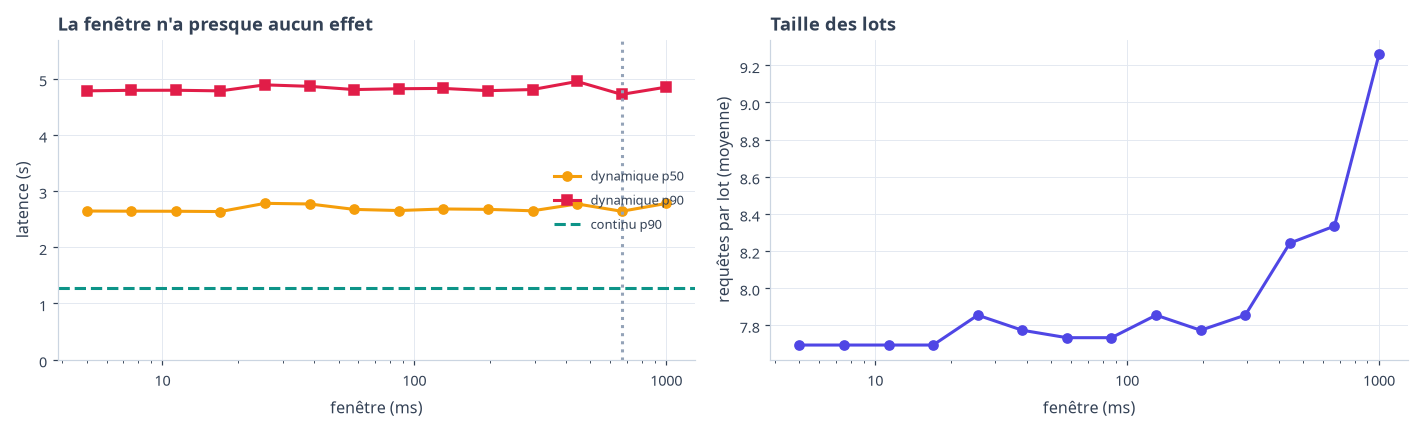

p90 : dynamique au mieux 4.72 s ; continu 1.27 s


In [7]:
cost = inf.StepCost(dec0=0.006, dec1=0.00005, pre0=0.005, pre1=0.000025)
w = inf.make_workload(1500, rate=5, seed=5)
windows = np.geomspace(0.005, 1.0, 14)
rows = []
for win in windows:
    r = inf.simulate_batching(w, "dynamic", max_batch=16, window=win, cost=cost)
    n_batches = r["debut"].nunique()
    rows.append(dict(fenêtre=win, p50=r["latence"].median(), p90=r["latence"].quantile(0.9),
                     lot_moyen=len(r) / n_batches))
dyn = pd.DataFrame(rows)
cont = inf.simulate_batching(w, "continuous", max_batch=16, cost=cost)
best = dyn.loc[dyn["p90"].idxmin()]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.plot(dyn["fenêtre"] * 1e3, dyn["p50"], "o-", color=AMBER, label="dynamique p50")
ax.plot(dyn["fenêtre"] * 1e3, dyn["p90"], "s-", color=ROSE, label="dynamique p90")
ax.axhline(cont["latence"].quantile(0.9), color=TEAL, ls="--", label="continu p90")
ax.axvline(best["fenêtre"] * 1e3, color=GRAY, ls=":")
ax.set_xscale("log"); plain_log_axis(ax, "x"); ax.set_ylim(0, dyn["p90"].max() * 1.15)
ax.set_xlabel("fenêtre (ms)"); ax.set_ylabel("latence (s)"); ax.legend(fontsize=8.5, loc="center right")
ax.set_title("La fenêtre n'a presque aucun effet")
ax = axes[1]
ax.plot(dyn["fenêtre"] * 1e3, dyn["lot_moyen"], "o-", color=INDIGO)
ax.set_xscale("log"); plain_log_axis(ax, "x")
ax.set_xlabel("fenêtre (ms)"); ax.set_ylabel("requêtes par lot (moyenne)"); ax.set_title("Taille des lots")
plt.tight_layout(); plt.show()
print(f"p90 : dynamique au mieux {best['p90']:.2f} s ; continu {cont['latence'].quantile(0.9):.2f} s")

**Lecture.** Surprise : la fenêtre ne change presque rien, ni au p90 ni (sauf pour les
fenêtres les plus longues) à la taille des lots. La raison : un lot naïf dure longtemps
(jusqu'à la fin de sa réponse la plus longue, souvent plusieurs centaines de pas) ; pendant
ce temps, les nouvelles requêtes s'accumulent, et le lot suivant part dès que le serveur se
libère avec toutes les requêtes en attente. La fenêtre n'agit que lorsque le serveur est
inoccupé, ce qui arrive rarement à cette charge. Le p90 est dominé par l'autre défaut du
batching naïf : attendre la réponse la plus longue du lot. Le batching continu, qui n'a pas
ce défaut, divise le p90 par un facteur de l'ordre de 3 ou 4.

> **À retenir.** La fenêtre du batching dynamique ne compte que lorsque le serveur attend
> (faible charge) ; pour des LLM aux réponses de longueurs très variables, le vrai levier
> est le batching **continu**.

## Exercice 9.11 : Rentabilité du cache de prompt

**Énoncé.**

1. Tarification de type Gemini : tokens en cache facturés 25 % du prix normal ($p$ =
   1,25 \$ par million de tokens d'entrée), plus un stockage de 1 \$ par million de tokens
   et par heure. Pour un préfixe de $C$ tokens, à partir de combien de requêtes par heure
   le cache est-il rentable ? Cela dépend-il de $C$ ?
2. Tarification de type Anthropic : écriture à 125 %, lecture à 10 %, durée de vie de
   5 minutes renouvelée à chaque lecture. Les requêtes arrivent selon un processus de
   Poisson de taux $\lambda$ par minute. Exprimer le coût moyen d'entrée par requête et
   tracer l'économie en fonction de $\lambda$.
3. Mini-lab : mesurer sur Qwen2.5-0.5B le TTFT avec et sans cache en fonction de la
   longueur du préfixe.

**Rappels.** Cache de prompt (cours 4, section 5 ; section *Prompt caching*, tableau 9-3).
Pour un processus de Poisson de taux $\lambda$, le délai jusqu'à la prochaine arrivée est
exponentiel : $P(\text{délai} \le T) = 1 - e^{-\lambda T}$.

**Solution.**

1. Économie par requête : $0{,}75\,p\,C/10^6$ ; coût de stockage par heure : $1 \times
   C/10^6$. Le cache est rentable si $r \cdot 0{,}75\,p > 1$, soit $r > 1/(0{,}75 \times
   1{,}25) \approx 1{,}07$ requête par heure, **indépendamment de $C$** (les deux termes
   sont proportionnels à $C$).
2. Une requête trouve le cache encore valide si la précédente date de moins de $T = 5$
   min : probabilité $q = 1 - e^{-5\lambda}$. Coût moyen d'entrée du préfixe :
   $p\,C\,[\,q \times 0{,}1 + (1 - q) \times 1{,}25\,]$ contre $p\,C$ sans cache.
   Économie $= 1 - [0{,}1\,q + 1{,}25\,(1 - q)]$, positive dès que $q > 0{,}25/1{,}15
   \approx 0{,}22$, c'est-à-dire $\lambda > -\ln(0{,}78)/5 \approx 0{,}05$ requête par
   minute (environ 3 par heure). $\blacksquare$

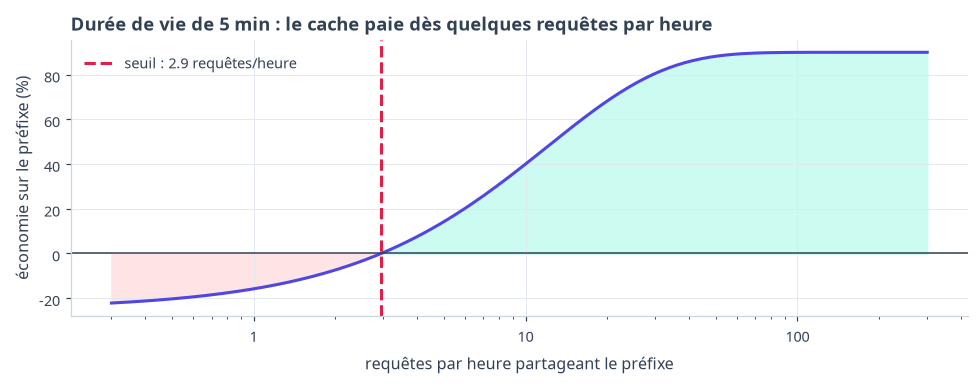

In [8]:
lam = np.geomspace(0.005, 5, 200)
q = 1 - np.exp(-5 * lam)
saving = 1 - (0.1 * q + 1.25 * (1 - q))
lam0 = -np.log(1 - 0.25 / 1.15) / 5
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(lam * 60, saving * 100, color=INDIGO)
ax.axhline(0, color=SLATE, lw=1); ax.axvline(lam0 * 60, color=ROSE, ls="--",
                                              label=f"seuil : {lam0 * 60:.1f} requêtes/heure")
ax.fill_between(lam * 60, saving * 100, 0, where=saving < 0, color=LIGHT[ROSE])
ax.fill_between(lam * 60, saving * 100, 0, where=saving > 0, color=LIGHT[TEAL])
ax.set_xscale("log"); plain_log_axis(ax, "x")
ax.set_xlabel("requêtes par heure partageant le préfixe"); ax.set_ylabel("économie sur le préfixe (%)")
ax.set_title("Durée de vie de 5 min : le cache paie dès quelques requêtes par heure"); ax.legend()
plt.tight_layout(); plt.show()

**Vérification expérimentale** (question 3).

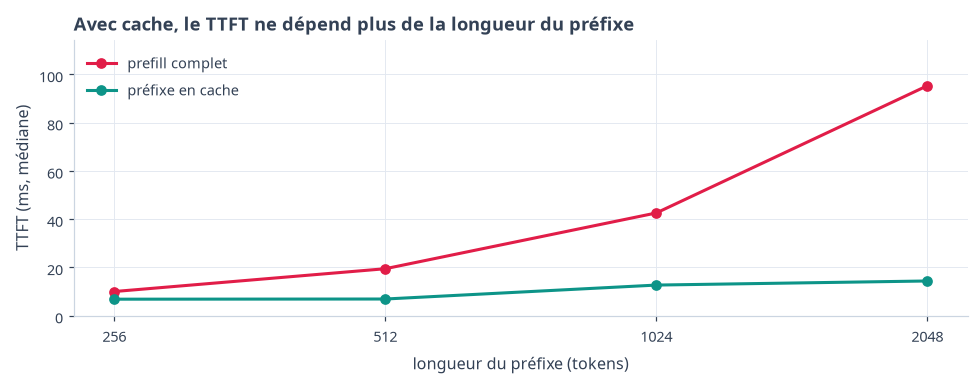

In [9]:
tok, model = inf.retry_oom(llm.load, llm.SMALL)


def ttft_vs_prefix():
    rows = []
    q_ids = tok(" What is the main idea?", return_tensors="pt")["input_ids"].cuda()
    with torch.no_grad():
        for n in [256, 512, 1024, 2048]:
            pre = inf.random_ids(1, n, seed=n)
            cache = model(pre, use_cache=True, logits_to_keep=1).past_key_values
            full = torch.cat([pre, q_ids], 1)

            def cached():
                model(q_ids, cache=cache, use_cache=True, logits_to_keep=1)
                inf._crop_to(cache, n)

            rows.append({"préfixe": n,
                         "sans cache (ms)": inf.time_fn(lambda: model(full, logits_to_keep=1), repeats=5)["median"] * 1e3,
                         "avec cache (ms)": inf.time_fn(cached, repeats=5)["median"] * 1e3})
            del cache
    return pd.DataFrame(rows)


tv = inf.retry_oom(ttft_vs_prefix)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(tv["préfixe"], tv["sans cache (ms)"], "o-", color=ROSE, label="prefill complet")
ax.plot(tv["préfixe"], tv["avec cache (ms)"], "o-", color=TEAL, label="préfixe en cache")
ax.set_xscale("log", base=2); plain_log_axis(ax, "x"); ax.set_ylim(0, tv["sans cache (ms)"].max() * 1.2)
ax.set_xlabel("longueur du préfixe (tokens)"); ax.set_ylabel("TTFT (ms, médiane)")
ax.set_title("Avec cache, le TTFT ne dépend plus de la longueur du préfixe"); ax.legend()
plt.tight_layout(); plt.show()

Sans cache, le TTFT croît avec le préfixe ; avec le cache, il reste celui d'un prefill de
quelques tokens (il augmente à peine, car l'attention des nouveaux tokens lit un cache plus
long).

> **À retenir.** Le cache de prompt est rentable dès que le même préfixe revient plus
> souvent que sa durée de vie (ou que le loyer de stockage) ne coûte ; son gain de latence
> est d'autant plus grand que le préfixe est long.

In [10]:
llm.free_gpu()
del model

## Exercice 9.12 : Répartir Llama 3-70B sur 8 GPU

**Énoncé.** On dispose d'un nœud de 8 H100 (80 Go, 3,35 To/s, NVLink) pour servir Llama
3-70B en bf16 (141 Go). Configurations candidates : 4 répliques en tenseur 2 (TP2 x 4),
2 répliques en TP4, 1 réplique en TP8, et 1 réplique en pipeline 2 x tenseur 4 (PP2-TP4).
Hypothèses : MBU de 70 % ; chaque *all-reduce* (2 par couche, 80 couches) coûte 10 µs plus
le transfert de $B \times d$ valeurs bf16 en anneau sur NVLink (~450 Go/s) ; une frontière de
pipeline coûte 20 µs plus le transfert des activations ; contexte de 4 096 tokens par
requête ; marge de 10 %.

1. Pour chaque configuration : latence d'un token à faible charge (lot de 1), nombre
   maximal de requêtes simultanées (mémoire), et débit total du nœud à pleine charge.
2. Laquelle choisir pour un assistant conversationnel (TPOT) ? Pour un traitement batch
   nocturne (débit) ?

**Rappels.** Parallélisme (cours 4, section 6 ; section *Parallelism*) : en tenseur, chaque
GPU lit $1/p$ des poids mais il faut communiquer ; le pipeline ne réduit pas la latence
d'un token (les étages travaillent en série) mais ajoute des frontières ; les répliques
multiplient la capacité.

**Solution.** Pour une réplique de $g$ GPU avec $t$ GPU en tenseur et $s = g/t$ étages :
un pas de decode lit $W/g$ octets par GPU... mais les étages s'enchaînent, donc la durée
d'un pas est $s \times \frac{W/g + \text{KV}/g}{0{,}7\,\beta} + \text{comm.}$, soit
$\frac{W + \text{KV}}{t \cdot 0{,}7\,\beta}$ : seul le degré de **tenseur** réduit la
latence. La mémoire disponible pour le cache vaut $0{,}9 \times 80 g - W$ par réplique.

configuration,GPU / réplique,TPOT lot 1 (ms),requêtes max / réplique,TPOT à pleine charge (ms),débit du nœud (tokens/s)
TP2 x 4 répliques,2,32.0,2,32.3,248
TP4 x 2 répliques,4,16.8,109,33.2,"6,568"
TP8 x 1,8,9.2,324,35.6,"9,100"
PP2-TP4 x 1,8,16.8,324,65.9,"8,009"


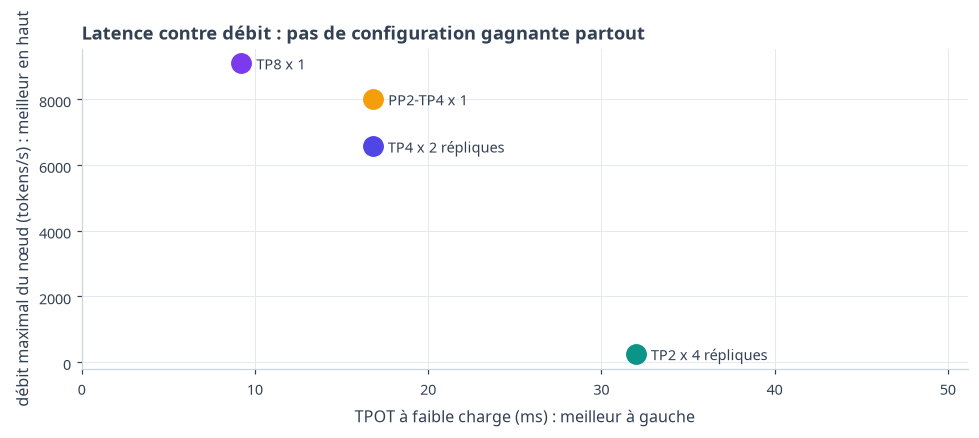

In [11]:
cfg70 = KNOWN_CONFIGS["Llama 3-70B"]
W70 = count_params_config(cfg70) * 2
kv_req = kv_cache_bytes(cfg70, 4096)
bw = 0.7 * H100["bw"]
configs = {"TP2 x 4 répliques": (2, 1, 4), "TP4 x 2 répliques": (4, 1, 2), "TP8 x 1": (8, 1, 1),
           "PP2-TP4 x 1": (4, 2, 1)}
rows = []
for name, (t, s, n_rep) in configs.items():
    g = t * s
    mem_kv = 0.9 * 80e9 * g - W70
    B_max = int(mem_kv // kv_req)

    def comm(B):
        """2 all-reduce par couche : latence fixe + volume (anneau, B x d valeurs bf16, NVLink ~450 Go/s)
        ; plus le transfert des activations à chaque frontière de pipeline."""
        ar = 2 * cfg70.n_layers * (10e-6 + 2 * (t - 1) / t * B * cfg70.d_model * 2 / 450e9) if t > 1 else 0.0
        return ar + (s - 1) * (20e-6 + B * cfg70.d_model * 2 / 450e9)

    def step(B):
        return (W70 + B * kv_req) / (t * bw) + comm(B)

    rows.append({"configuration": name, "GPU / réplique": g, "TPOT lot 1 (ms)": step(1) * 1e3,
                 "requêtes max / réplique": B_max,
                 "TPOT à pleine charge (ms)": step(B_max) * 1e3,
                 # pipeline plein : s micro-lots de B_max/s séquences ; chaque étage lit W/s poids par micro-lot
                 "débit du nœud (tokens/s)": n_rep * B_max / ((W70 + B_max * kv_req / s) / (t * bw) + comm(B_max) / s)})
t912 = pd.DataFrame(rows)
display(t912.style.format({"TPOT lot 1 (ms)": "{:.1f}", "TPOT à pleine charge (ms)": "{:.1f}",
                           "débit du nœud (tokens/s)": "{:,.0f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(9, 4))
for (_, r_), c in zip(t912.iterrows(), [TEAL, INDIGO, VIOLET, AMBER]):
    ax.scatter(r_["TPOT lot 1 (ms)"], r_["débit du nœud (tokens/s)"], s=160, color=c, zorder=3)
    ax.annotate(r_["configuration"], (r_["TPOT lot 1 (ms)"], r_["débit du nœud (tokens/s)"]),
                textcoords="offset points", xytext=(10, -4), fontsize=9.5)
ax.set_xlabel("TPOT à faible charge (ms) : meilleur à gauche")
ax.set_ylabel("débit maximal du nœud (tokens/s) : meilleur en haut")
ax.set_xlim(0, t912["TPOT lot 1 (ms)"].max() * 1.6)
ax.set_title("Latence contre débit : pas de configuration gagnante partout")
plt.tight_layout(); plt.show()

**Lecture.**

- **TP8** donne la latence la plus faible (chaque GPU lit 1/8 des poids) et, dans ce
  modèle, aussi le meilleur débit : les poids ne sont stockés qu'une fois, ce qui laisse le
  plus de mémoire aux caches. Son coût est la communication, qui croît avec la taille du
  lot (voir le TPOT à pleine charge), et le fait de n'avoir qu'une réplique (une panne
  arrête tout) ;
- **TP4 x 2** double la latence d'un token et stocke les poids deux fois (moins de place
  pour les caches, donc moins de débit), mais offre deux répliques indépendantes :
  redondance et ordonnancement plus simple ;
- **TP2 x 4** tient à peine en mémoire (presque rien pour les caches) : inutilisable ;
- **PP2-TP4** a la mémoire de TP8 mais la latence de TP4, et son TPOT à pleine charge est le
  plus élevé (les étages s'enchaînent) : le pipeline n'a d'intérêt que lorsque les groupes
  de GPU ne sont pas reliés par un lien rapide (par exemple entre deux nœuds), et il faut
  alors assez de micro-lots pour limiter la bulle ($\frac{p-1}{m+p-1}$).

Pour un assistant conversationnel : TP8, ou TP4 x 2 si la redondance compte. Pour un
traitement batch dans un seul nœud : TP8 également ici ; au-delà d'un nœud, on ajoute du
pipeline ou des répliques.

Ces chiffres sont des bornes (MBU supposée, communication simplifiée) : en pratique on
confirme par des mesures, et l'on combine souvent les stratégies (le livre retient
tenseur et répliques parmi les techniques les plus rentables).

> **À retenir.** Le degré de **tenseur** fixe la latence d'un token ; le nombre de
> **répliques** et la mémoire libre pour les caches fixent le débit ; le **pipeline** sert
> le débit, pas la latence. Choisissez selon le SLO.